<a href="https://colab.research.google.com/github/niginadavronova/collab.works/blob/main/04_VISUAL_AMALIYOT_01_matplotlib_seaborn_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Imgur](https://i.imgur.com/5pXzCIu.png)

# Data Science va Sun'iy Intellekt Praktikum

## 4-MODUL. VIZUALIZASIYA

## 1-AMALIYOT. `matplotlib`


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [3]:
pip install seaborn

Ushbu amaliyot uchun https://en.tutiempo.net/climate/ws-384570.html sahifasidagi Toshkent shahri o'rtacha havo harorati haqidagi ma'lumotlardan foydalanamiz.

![](https://i.imgur.com/lCIRIYm.png)

In [ ]:
#@title QUYIDAGI KODGA TEGMANG!!!
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

## 1-VAZIFA: Sahifadagi jadvalni pandas dataframega aylantiring va:
### - Yil (`Year`) ustunini index sifatida o'qing.
### - 1990 yildan avvalgi ma'lumotlar tashlab yuboring.
### - natijani `df` degan o'zgaruvchiga saqlang

In [4]:
import requests

url = "https://en.tutiempo.net/climate/ws-384570.html"
headers = {"User-Agent": "Mozilla/5.0"}
html = requests.get(url, headers=headers).text

tables = pd.read_html(html, index_col=0)
print("Jadvallar soni:", len(tables))

for i, t in enumerate(tables):
  print(f"--- Jadval {i} ---")
  print(t.head(2))

/tmp/ipykernel_1080/3898537505.py:7: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(html, index_col=0)


Jadvallar soni: 2
--- Jadval 0 ---
      T TM Tm PP  V RA SN TS FG TN GR
Year                                 
1933  -  -  -  -  -  -  -  -  -  -  -
1934  -  -  -  -  -  -  -  -  -  -  -
--- Jadval 1 ---
                                          1
0                                          
T           Average annual temperature (°C)
TM  Annual average maximum temperature (°C)


In [10]:
# JAVOBNI SHUYERGA YOZING
df = tables[0].copy()
df.index = pd.to_numeric(df.index, errors="coerce")
df = df[df.index >= 1990]
df.head(7)

,T,TM,Tm,PP,V,RA,SN,TS,FG,TN,GR
Year,,,,,,,,,,,
1990,14.9,21.5,8.7,504.72,5.1,84,32,12,12,0,1
1991,14.4,21.2,8.3,460.52,5.1,77,26,15,17,0,1
1992,14.4,20.8,8.6,470.39,5.1,93,19,9,2,0,1
1993,13.4,19.6,7.6,710.97,5.4,98,38,12,10,1,0
1994,14.4,21.1,8,595.38,5.1,66,28,4,9,0,0
1995,15,22.2,8.4,189.99,4.4,41,20,8,12,0,0
1996,14,20.5,7.6,184.16,5,68,23,14,13,0,0


In [ ]:
#@title Kutilgan natija:

In [ ]:
#@title To'g'ri javob
tables = pd.read_html("https://en.tutiempo.net/climate/ws-384570.html", index_col=0)
# read_html sahifadagi har bir jadvallarni bitta ro'yxatga joylaydi,
# ro'yxatni tahlil qilib bizga kerak jadval [3] indeksda joylashganini bilsak bo'ladi
df = tables[3][tables[3].index>1990]
# df.head()

IndexError: list index out of range

## 2-VAZIFA. Har bir ustun nimani anglatishi ham yuqoridagi sahifada joylashgan. Shu jadvalni ham chiqaring. Matnlarni [Google translate](https://translate.google.com) orqali tarjima qilib, uqib oling.

In [5]:
# JAVOBNI SHUYERGA YOZING
tables[1]

,1
0,
T,Average annual temperature (°C)
TM,Annual average maximum temperature (°C)
Tm,Average annual minimum temperature (°C)
PP,Rain or snow precipitation total annual
V,Annual average wind speed (km/h)
RA,Number of days with rain
SN,Number of days with snow
TS,Number of days with storm
FG,Number of foggy days


In [ ]:
#@title Kutilgan natija:


In [ ]:
#@title To'g'ri javob:
# tables[4]

## 3-VAZIFA. `df`ni tahlil qilamiz

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 36 entries, 1990 to 2025
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   T       36 non-null     object
 1   TM      36 non-null     object
 2   Tm      36 non-null     object
 3   PP      36 non-null     object
 4   V       36 non-null     object
 5   RA      36 non-null     object
 6   SN      36 non-null     object
 7   TS      36 non-null     object
 8   FG      36 non-null     object
 9   TN      36 non-null     object
 10  GR      36 non-null     object
dtypes: object(11)
memory usage: 3.4+ KB


### **SAVOL**: Yuqoridagi natijadan qanday xulosaga kelish mumkin? DF dagi sonlar bilan ishlasak bo'ladimi?

In [ ]:
#@title JAVOB:
# Afsuski, jadvalda mavjud bo'lmagan qiymatlar o'rniga tire (-) belgisi qo'yib ketilgan,
# shu sababdan jadval ustunlari son (int, float) emas matn (object) bo'lib qolgan.

## 4-VAZIFA. `df`dagi barcha `-` belgilarni `NaN` qiymat bilan almashtiring.

In [12]:
# JAVOBNI SHUYERGA YOZIN
df=df.replace('-', np.nan)
df

,T,TM,Tm,PP,V,RA,SN,TS,FG,TN,GR
Year,,,,,,,,,,,
1990,14.9,21.5,8.7,504.72,5.1,84,32,12,12,0,1
1991,14.4,21.2,8.3,460.52,5.1,77,26,15,17,0,1
1992,14.4,20.8,8.6,470.39,5.1,93,19,9,2,0,1
1993,13.4,19.6,7.6,710.97,5.4,98,38,12,10,1,0
1994,14.4,21.1,8,595.38,5.1,66,28,4,9,0,0
1995,15,22.2,8.4,189.99,4.4,41,20,8,12,0,0
1996,14,20.5,7.6,184.16,5,68,23,14,13,0,0
1997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
df.isin(["-"])

,T,TM,Tm,PP,V,RA,SN,TS,FG,TN,GR
Year,,,,,,,,,,,
1990,False,False,False,False,False,False,False,False,False,False,False
1991,False,False,False,False,False,False,False,False,False,False,False
1992,False,False,False,False,False,False,False,False,False,False,False
1993,False,False,False,False,False,False,False,False,False,False,False
1994,False,False,False,False,False,False,False,False,False,False,False
1995,False,False,False,False,False,False,False,False,False,False,False
1996,False,False,False,False,False,False,False,False,False,False,False
1997,False,False,False,False,False,False,False,False,False,False,False
1998,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
#@title To'g'ri javob
df = df.replace("-", np.nan)

## 5-VAZIFA. `df` ustunlari qiymatlarini matndan o'nlik songa (`float`) o'zgartiring.

In [14]:
# JAVOBNI SHUYERGA YOZING
df=df.astype(float)
df

,T,TM,Tm,PP,V,RA,SN,TS,FG,TN,GR
Year,,,,,,,,,,,
1990,14.9,21.5,8.7,504.72,5.1,84.0,32.0,12.0,12.0,0.0,1.0
1991,14.4,21.2,8.3,460.52,5.1,77.0,26.0,15.0,17.0,0.0,1.0
1992,14.4,20.8,8.6,470.39,5.1,93.0,19.0,9.0,2.0,0.0,1.0
1993,13.4,19.6,7.6,710.97,5.4,98.0,38.0,12.0,10.0,1.0,0.0
1994,14.4,21.1,8.0,595.38,5.1,66.0,28.0,4.0,9.0,0.0,0.0
1995,15.0,22.2,8.4,189.99,4.4,41.0,20.0,8.0,12.0,0.0,0.0
1996,14.0,20.5,7.6,184.16,5.0,68.0,23.0,14.0,13.0,0.0,0.0
1997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
df.dtypes

,0
T,float64
TM,float64
Tm,float64
PP,float64
V,float64
RA,float64
SN,float64
TS,float64
FG,float64
TN,float64


In [ ]:
#@title To'g'ri javob:
df = df.astype(dtype='float')
df.head(10)

## 6-VAZIFA. `NaN` qiymatlar bilan ishlaymiz
### 6.1. Har bir ustundagi `NaN` qiymatlar soni va ularning proprosiyasini toping.

In [16]:
# JAVOBNI SHUYERGA YOZING
df.isnull().sum()/len(df)*100

,0
T,16.666667
TM,16.666667
Tm,16.666667
PP,72.222222
V,16.666667
RA,13.888889
SN,13.888889
TS,13.888889
FG,13.888889
TN,13.888889


In [ ]:
#@title Kutilgan natija
df.isnull().sum()/len(df)*100

### 6.2. Eng ko'p `nan` qiymat mavjud ustunni tashlab yuboring va natijani saqlab qoling.

In [17]:
# JAVOBNI SHUYERGA YOZING
df.columns

Index(['T', 'TM', 'Tm', 'PP', 'V', 'RA', 'SN', 'TS', 'FG', 'TN', 'GR'], dtype='object')

In [18]:
df=df.drop(columns='PP')
df.head()

,T,TM,Tm,V,RA,SN,TS,FG,TN,GR
Year,,,,,,,,,,
1990,14.9,21.5,8.7,5.1,84.0,32.0,12.0,12.0,0.0,1.0
1991,14.4,21.2,8.3,5.1,77.0,26.0,15.0,17.0,0.0,1.0
1992,14.4,20.8,8.6,5.1,93.0,19.0,9.0,2.0,0.0,1.0
1993,13.4,19.6,7.6,5.4,98.0,38.0,12.0,10.0,1.0,0.0
1994,14.4,21.1,8.0,5.1,66.0,28.0,4.0,9.0,0.0,0.0


In [ ]:
#@title To'g'ri javob
df.drop('PP', axis=1, inplace=True)
df.head()

### 6.3. Qolgan `NaN` qiymatlarni o'zingiz to'g'ri deb bilgan usulda to'ldiring (tashlab yubormang) va natijani saqlab qoling.

In [19]:
# JAVOBNI SHUYERGA YOZING
df=df.ffill()
df

,T,TM,Tm,V,RA,SN,TS,FG,TN,GR
Year,,,,,,,,,,
1990,14.9,21.5,8.7,5.1,84.0,32.0,12.0,12.0,0.0,1.0
1991,14.4,21.2,8.3,5.1,77.0,26.0,15.0,17.0,0.0,1.0
1992,14.4,20.8,8.6,5.1,93.0,19.0,9.0,2.0,0.0,1.0
1993,13.4,19.6,7.6,5.4,98.0,38.0,12.0,10.0,1.0,0.0
1994,14.4,21.1,8.0,5.1,66.0,28.0,4.0,9.0,0.0,0.0
1995,15.0,22.2,8.4,4.4,41.0,20.0,8.0,12.0,0.0,0.0
1996,14.0,20.5,7.6,5.0,68.0,23.0,14.0,13.0,0.0,0.0
1997,14.0,20.5,7.6,5.0,68.0,23.0,14.0,13.0,0.0,0.0
1998,14.0,20.5,7.6,5.0,68.0,23.0,14.0,13.0,0.0,0.0


In [ ]:
#@title Javobga misol:
df.fillna(method='ffill', inplace=True)
df

### 6.4. Yakuniy `df` ni csv faylga saqlab, kompyuterga (yoki githubga) yuklab oling (keyingi darsda ishlatamiz)

In [20]:
# JAVOBNI SHUYERGA YOZING
df.to_csv('climatena.csv', index=False)

In [ ]:
#@title Javob
df.to_csv("tashtemp.csv")

##7-VAZIFA. Chiziqli grafiklar

### 7.1. `df`dan yillik o'rtacha haroratni ko'rsatuvchi ustunni `x` o'zgaruvchiga saqlang va `plt.plot()` yordamida chiziqli grafik chizing.

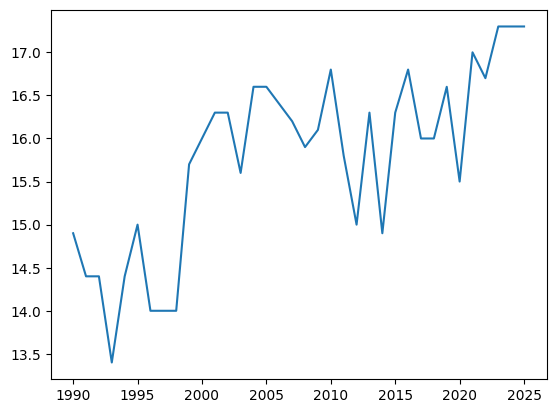

In [ ]:
# JAVOBNI SHUYERGA YOZING
import matplotlib.pyplot as plt
%matplotlib inline
x=df['T']
plt.plot(x)
plt.show()

In [ ]:
#@title To'g'ri javob
import matplotlib.pyplot as plt
%matplotlib inline
x=df['T']
plt.plot(x)
plt.show()

### 7.2. Yuqoridagi grafikni hajmini kattalashtiring, chiziq qalingligi, turi, rangi, markerlar turini istalgancha o'zgartiring

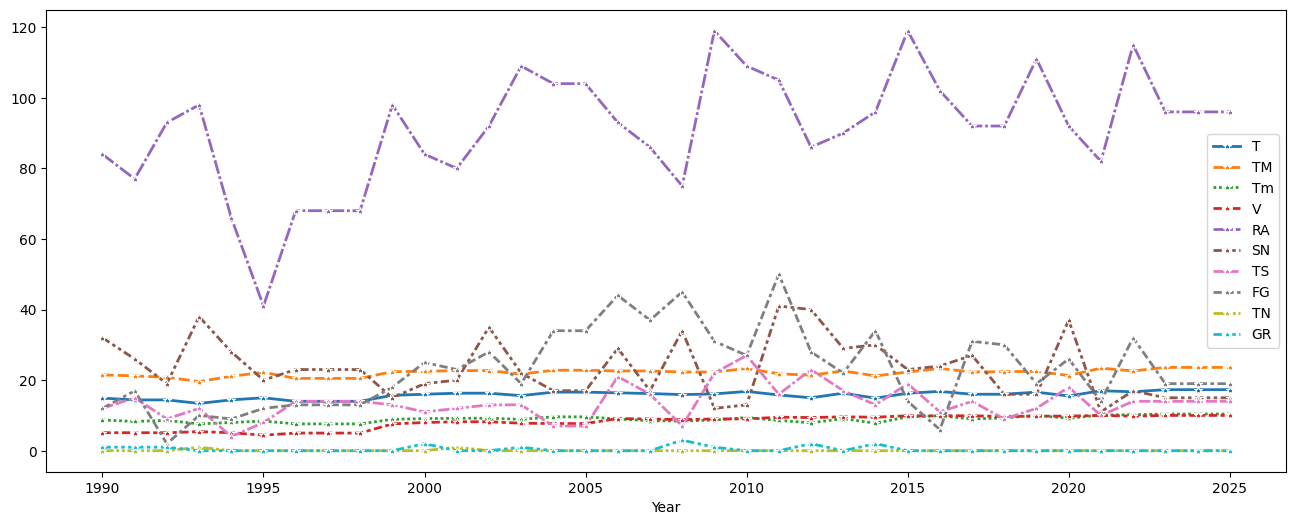

In [ ]:
# JAVOBNI SHUYERGA YOZING
plt.figure(figsize=(16, 6))
sns.lineplot(
    data=df,
    linestyle="-",
    linewidth=2,
    color="r",
    marker="*"
)
plt.show()

In [ ]:
#@title Javobga misol:
x=df['T']
plt.figure(figsize=(16,8))
plt.plot(x, linewidth=2, linestyle="--", marker='h', markerfacecolor='r')
plt.show()

### 7.3. Yuqoridagi grafikda x va y o'qlarini nomlang, grafikka ham umumiy nom bering

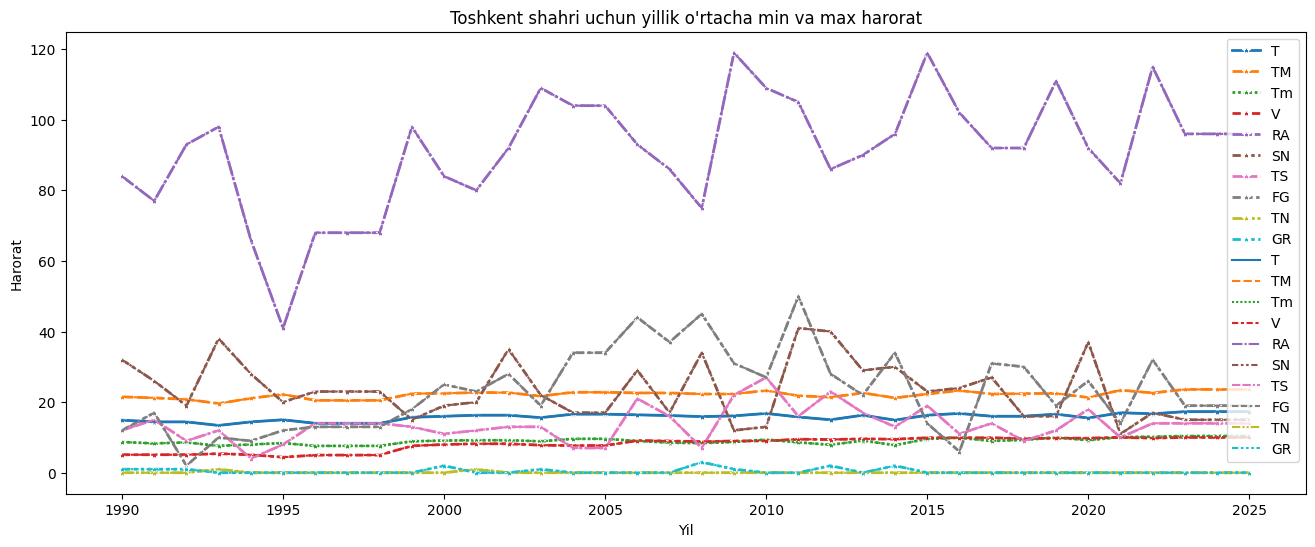

In [ ]:
# JAVOBNI SHUYERGA YOZING
plt.figure(figsize=(16, 6))
sns.lineplot(
    data=df,
    linestyle="-",
    linewidth=2,
    color="r",
    marker="*"
)
plt.xlabel("Yil")
plt.ylabel("Harorat")
plt.title("Toshkent shahri uchun yillik o'rtacha min va max harorat")
sns.lineplot(data=df)
plt.show()

In [ ]:
#@title To'g'ri javob
x=df['T']
plt.figure(figsize=(16,8))
plt.plot(x, linewidth=2, linestyle="--", marker='h', markerfacecolor='r')
plt.title("Toshkent shahri uchun yillik o'rtacha harorat")
plt.xlabel("Yil")
plt.ylabel("Harorat")
plt.show()

## 8-VAZIFA. Toshkent shahri uchun, har bir yilda o'rtacha min va max haroratlarni ko'rsatuvchi grafik chizing. **Grafikni faylga saqlab oling**

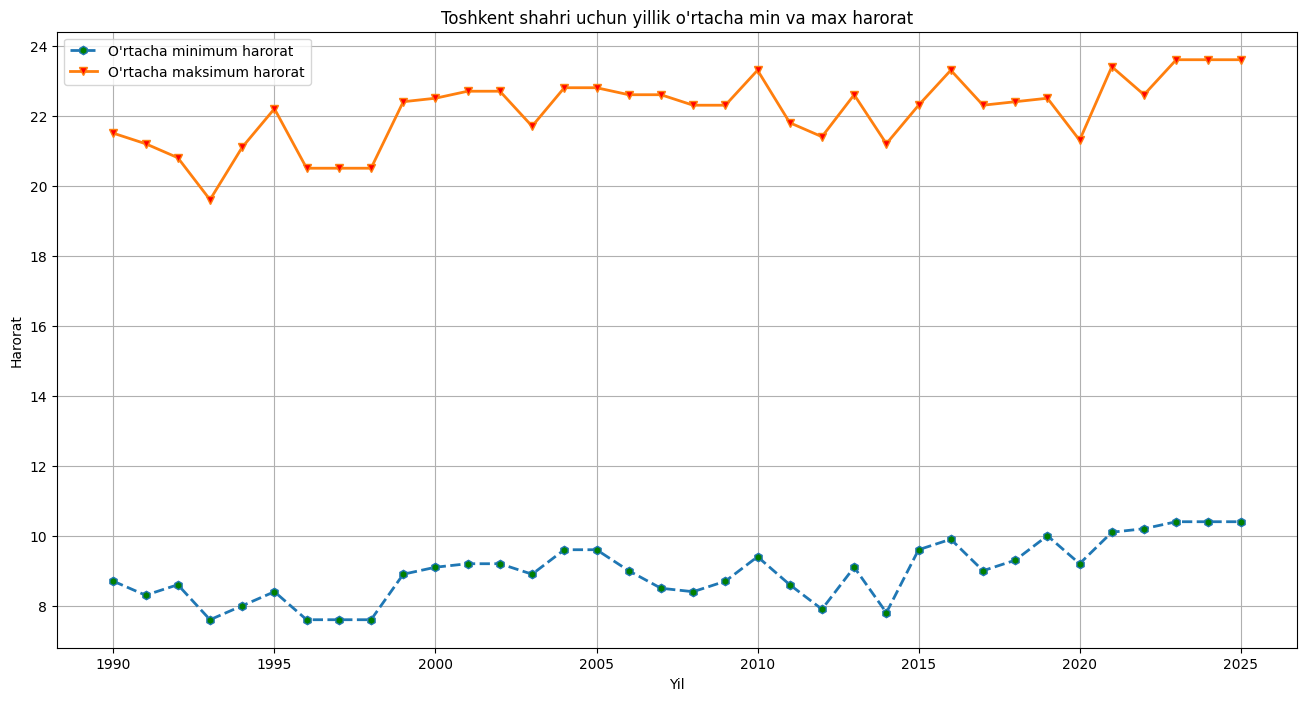

In [ ]:
# JAVOBNI SHUYERGA YOZING
#@title To'g'ri javob
minT = df['Tm']
maxT = df['TM']
plt.figure(figsize=(16,8))
plt.plot(minT, linewidth=2, linestyle="--", marker='h', markerfacecolor='g', label="O'rtacha minimum harorat")
plt.plot(maxT, linewidth=2, linestyle="-", marker='v', markerfacecolor='r', label="O'rtacha maksimum harorat")
plt.grid()
plt.legend()
plt.title("Toshkent shahri uchun yillik o'rtacha min va max harorat")
plt.xlabel("Yil")
plt.ylabel("Harorat")
plt.savefig('tempMinMax.png')
plt.show()

In [ ]:
#@title To'g'ri javob
minT = df['Tm']
maxT = df['TM']
plt.figure(figsize=(16,8))
plt.plot(minT, linewidth=2, linestyle="--", marker='h', markerfacecolor='g', label="O'rtacha minimum harorat")
plt.plot(maxT, linewidth=2, linestyle="-", marker='v', markerfacecolor='r', label="O'rtacha maksimum harorat")
plt.grid()
plt.legend()
plt.title("Toshkent shahri uchun yillik o'rtacha min va max harorat")
plt.xlabel("Yil")
plt.ylabel("Harorat")
plt.savefig('tempMinMax.png')
plt.show()

## 9-VAZIFA. Faylga saqlangan grafikni ochib ko'ring.

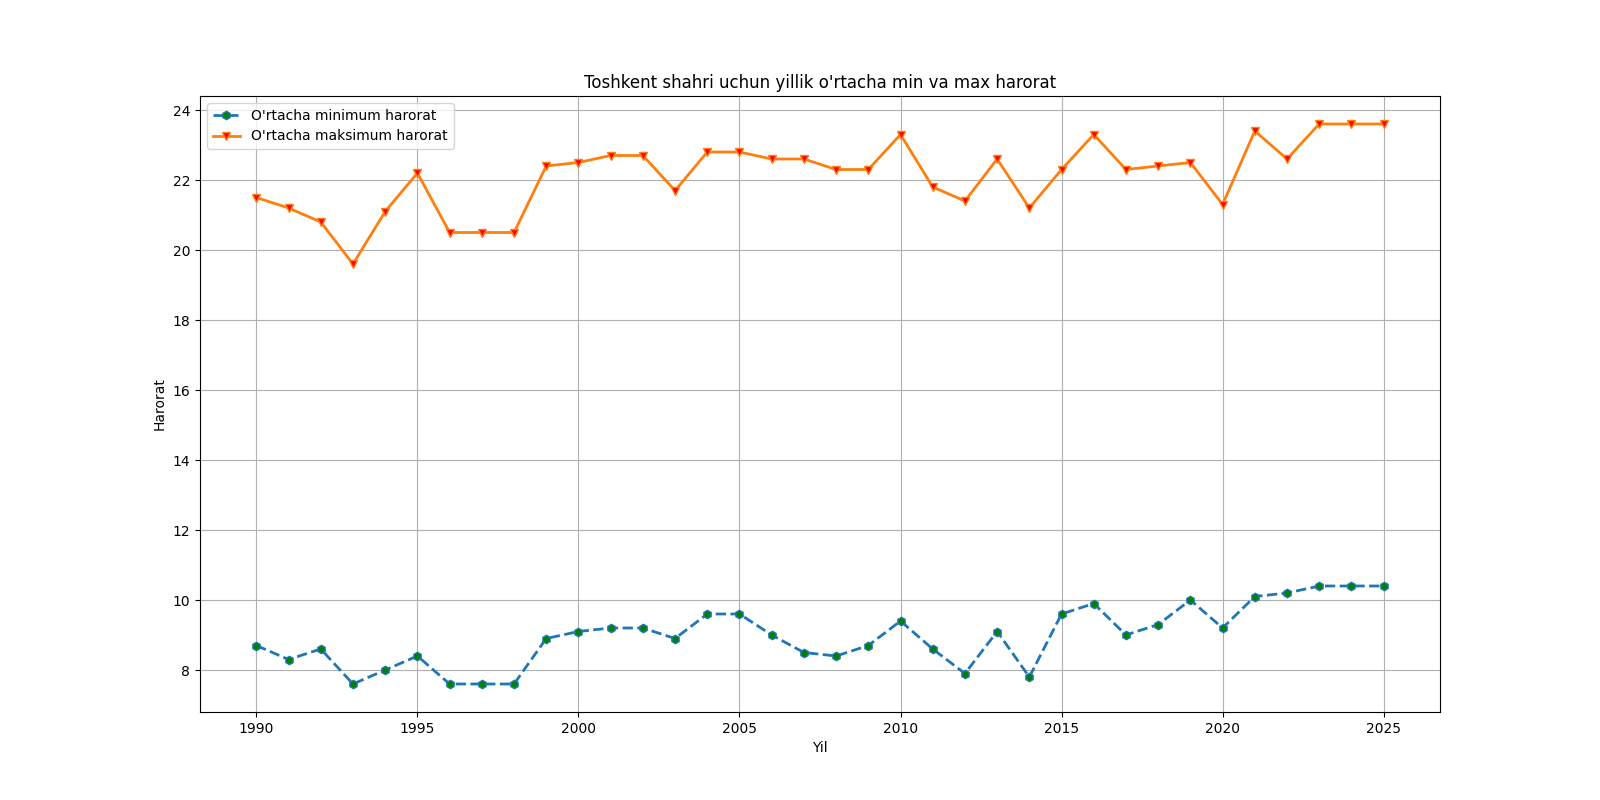

In [ ]:
# JAVOBNI SHUYERGA YOZING
from IPython.display import Image
Image("tempMinMax.png")

In [ ]:
#@title Javob
from IPython.display import Image
Image('tempMinMax.png')